# CXC1

In [12]:
import os 
from dotenv import load_dotenv
from tensorflow.keras import layers, models
import tensorflow as tf 

In [13]:
print("Tensorflow version: ", tf.__version__)
print("GPU's: ", tf.config.list_physical_devices("GPU"))

Tensorflow version:  2.16.1
GPU's:  [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### Variables and Contanst

In [ ]:
load_dotenv() # load data from .env file 

dataset_path = os.getenv("DATASET_DIR")
model_path = os.getenv("MODEL_DIR")

MODEL_NAME = "CXC1.keras"
model_path = os.path.join(model_path, MODEL_NAME)

train_data_dir = os.path.join(dataset_path, "data03", "train")
test_data_dir = os.path.join(dataset_path, "data03", "test")
val_data_dir = os.path.join(dataset_path, "data03", "val")


# Set parameters
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

print(train_data_dir)
print(test_data_dir)
print(val_data_dir)

/Users/joshan/Documents/final-year-project/dataset/data03/train
/Users/joshan/Documents/final-year-project/dataset/data03/test
/Users/joshan/Documents/final-year-project/dataset/data03/val


### Load dataset 

In [10]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_data_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical' # Important for 3-class classification
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_data_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical'
)

val_ds = tf.keras.utils.image_dataset_from_directory(
   val_data_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical'
)

Found 13028 files belonging to 4 classes.
Found 1527 files belonging to 4 classes.
Found 761 files belonging to 4 classes.


### EDA on dataset

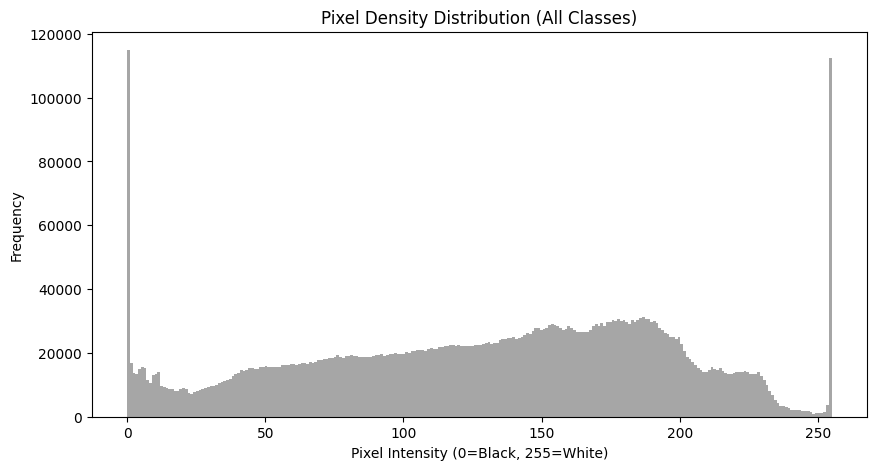

2026-04-02 14:34:24.033598: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


In [10]:
import matplotlib.pyplot as plt
import numpy as np

# Take one batch (e.g., 32 images)
for images, labels in train_ds.take(1):
    # Flatten all pixels in the batch into a 1D array
    pixels = images.numpy().flatten()
    
    plt.figure(figsize=(10, 5))
    plt.hist(pixels, bins=256, color='gray', alpha=0.7)
    plt.title('Pixel Density Distribution (All Classes)')
    plt.xlabel('Pixel Intensity (0=Black, 255=White)')
    plt.ylabel('Frequency')
    plt.show()

### CNN model Architecture

In [ ]:
model = models.Sequential([
    # Preprocessing: Rescale inputs to [0, 1]
    layers.Rescaling(1./255, input_shape=(224, 224, 3)),
    
    # First convolutional Block
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    
    # Second convolutional Block
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    
    # Third convolutional Block
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    
    # Flatten and Classify
    layers.Flatten(),
    layers.Dense(128, activation='relu'),  
    layers.Dropout(0.5), # Helps prevent overfitting by dropping out 0.5 acc 
    layers.Dense(4, activation='softmax') # Softmax for multi-class probability
])

/Users/joshan/Documents/final-year-project/backend/.venv/lib/python3.11/site-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [14]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Train the model
history = model.fit(
    train_ds,
    validation_data=val_ds, # evaluating against val dataset
    epochs=10
)

Epoch 1/10


2026-04-02 14:35:10.859560: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


408/408 ━━━━━━━━━━━━━━━━━━━━ 48s 112ms/step - accuracy: 0.7969 - loss: 0.5664 - val_accuracy: 0.8949 - val_loss: 0.2793
Epoch 2/10
408/408 ━━━━━━━━━━━━━━━━━━━━ 45s 111ms/step - accuracy: 0.8737 - loss: 0.3996 - val_accuracy: 0.9014 - val_loss: 0.2750
Epoch 3/10
408/408 ━━━━━━━━━━━━━━━━━━━━ 55s 134ms/step - accuracy: 0.9004 - loss: 0.3472 - val_accuracy: 0.9185 - val_loss: 0.2618
Epoch 4/10
408/408 ━━━━━━━━━━━━━━━━━━━━ 50s 123ms/step - accuracy: 0.9120 - loss: 0.2950 - val_accuracy: 0.9382 - val_loss: 0.5072
Epoch 5/10
408/408 ━━━━━━━━━━━━━━━━━━━━ 51s 124ms/step - accuracy: 0.9077 - loss: 0.3498 - val_accuracy: 0.9185 - val_loss: 0.2341
Epoch 6/10
408/408 ━━━━━━━━━━━━━━━━━━━━ 49s 120ms/step - accuracy: 0.9142 - loss: 0.3192 - val_accuracy: 0.9488 - val_loss: 0.2087
Epoch 7/10
408/408 ━━━━━━━━━━━━━━━━━━━━ 50s 121ms/step - accuracy: 0.9189 - loss: 0.3187 - val_accuracy: 0.9133 - val_loss: 0.3685
Epoch 8/10
408/408 ━━━━━━━━━━━━━━━━━━━━ 48s 117ms/step - accuracy: 0.9189 - loss: 0.3437 - val

### Save Model

In [15]:
# Save the model
model.save('CXC1.keras')
print("Model saved successfully!")

Model saved successfully!


### Evaluating model against test and validation dataset 

In [16]:
# Evaludate against test data
results = model.evaluate(test_ds)
print(f"Test Loss: {results[0]}")
print(f"Test Accuracy: {results[1]*100:.2f}%")

48/48 ━━━━━━━━━━━━━━━━━━━━ 2s 42ms/step - accuracy: 0.9450 - loss: 0.2807
Test Loss: 0.2806786894798279
Test Accuracy: 94.50%


In [19]:
results = model.evaluate(val_ds)
print(f"Test Loss: {results[0]}")
print(f"Test Accuracy: {results[1]*100:.2f}%")

24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - accuracy: 0.9264 - loss: 0.6633
Test Loss: 0.6633321046829224
Test Accuracy: 92.64%


### Confussion Matrix for the model on test dataset

2026-04-02 14:48:40.815386: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


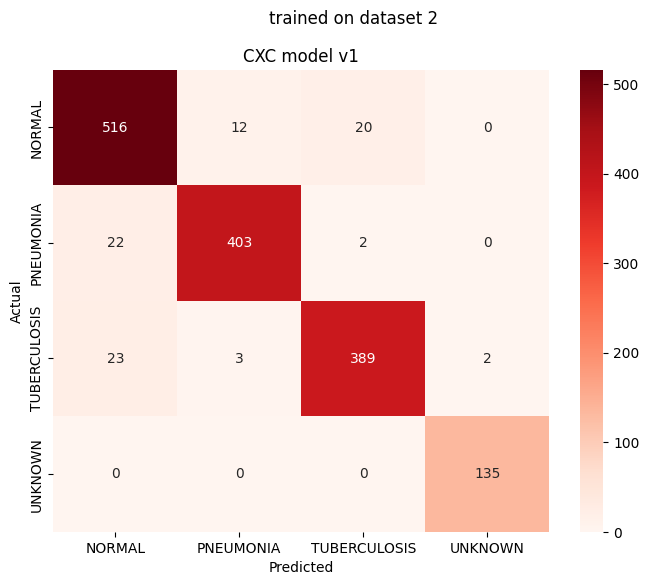

              precision    recall  f1-score   support

      NORMAL       0.92      0.94      0.93       548
   PNEUMONIA       0.96      0.94      0.95       427
TUBERCULOSIS       0.95      0.93      0.94       417
     UNKNOWN       0.99      1.00      0.99       135

    accuracy                           0.94      1527
   macro avg       0.95      0.95      0.95      1527
weighted avg       0.95      0.94      0.95      1527



In [17]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# Get all predictions and true labels
y_pred = []
y_true = []

for images, labels in test_ds:
    preds = model.predict(images, verbose=0)
    y_pred.extend(np.argmax(preds, axis=1))
    y_true.extend(np.argmax(labels, axis=1))

# Generate the Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
class_names = test_ds.class_names

# Plot them in heat map
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds', 
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('CXC model v1')
plt.suptitle("trained on dataset 2")
plt.show()

# Print Precision, Recall, and F1-Score
print(classification_report(y_true, y_pred, target_names=class_names))

# POC: AdamW is better than Adam in terms of accuracy 

2026-02-24 11:40:46.956724: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


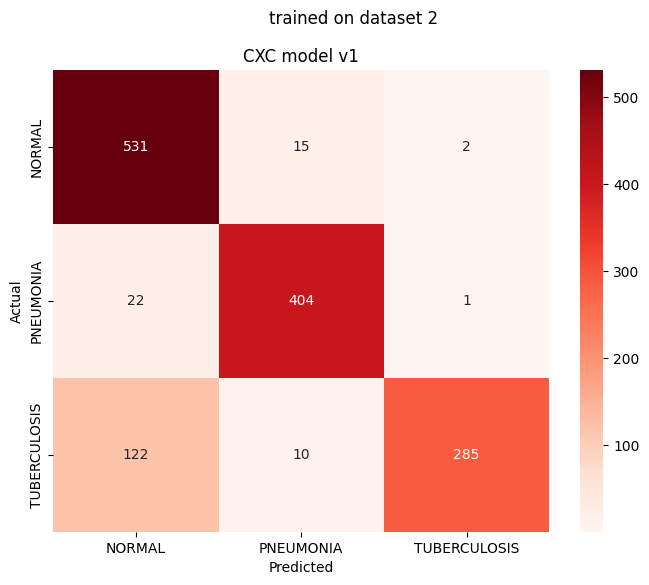

              precision    recall  f1-score   support

      NORMAL       0.79      0.97      0.87       548
   PNEUMONIA       0.94      0.95      0.94       427
TUBERCULOSIS       0.99      0.68      0.81       417

    accuracy                           0.88      1392
   macro avg       0.91      0.87      0.87      1392
weighted avg       0.90      0.88      0.87      1392



In [9]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# Get all predictions and true labels
y_pred = []
y_true = []

for images, labels in test_ds:
    preds = model2.predict(images, verbose=0)
    y_pred.extend(np.argmax(preds, axis=1))
    y_true.extend(np.argmax(labels, axis=1))

# Generate the Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
class_names = test_ds.class_names

# Plot them in heat map
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds', 
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('CXC model v1')
plt.suptitle("trained on dataset 2")
plt.show()

# Print Precision, Recall, and F1-Score
print(classification_report(y_true, y_pred, target_names=class_names))